# Quantum Machine Learning from primitives

A quantum machine learning model is a parameterized quantum circuit. Its parameters are tuned to fit data. In this tutorial we build one from the ground up out of the primitives in `qrisp.qml`. We train it, and then we vary each part in turn.

There is no model class to instantiate and no training loop to inherit. A model here is an ordinary Python function, the loss is one too, and training is a call to `qrisp.jasp.minimize`. We assemble everything explicitly, which means every part can be replaced.

The figure shows the whole pipeline for the model we build here, with two features on two qubits. Throughout, we write vectors underlined, such as the features $\underline{x} = (x_0, x_1)$ of one sample and the parameters $\underline{w}$. We write their components in plain italic, such as $x_0$.

<p align="center"><img src="../../_static/qml_pipeline.svg" alt="The QML pipeline. The features x enter the encoding S(x). The ansatz W(w) acts on the encoded state. Qubit 0 is measured in Z to give the prediction f(x, w). The loss compares predictions with labels. The optimizer updates w." width="800"></p>

Read it from left to right.

- The encoding $S(\underline{x})$ comes first. A quantum circuit cannot take numbers as input directly, and the encoding therefore writes the features into the qubits. Each feature becomes the angle of a rotation $R_Y(x_i)$, which turns the starting state $\ket{00}$ into a state $\ket{\psi(\underline{x})}$ that depends on the data.
- Next comes the ansatz $W(\underline{w})$, a circuit of rotations with adjustable angles $\underline{w}$ and a CX gate that lets the two qubits influence each other. The ansatz plays the role of the weights in a neural network. The data decide where the state starts, and $\underline{w}$ decides how it is transformed into $\ket{\psi(\underline{x}, \underline{w})}$.
- Then comes the measurement. A quantum state cannot be read out directly, which is why we measure qubit 0 many times and average the results. This gives the expectation value $f(\underline{x}; \underline{w}) = \langle \psi(\underline{x}, \underline{w}) | Z_0 | \psi(\underline{x}, \underline{w}) \rangle$, a number between $-1$ and $+1$ that is the prediction of the model.
- The loss $L(\underline{w})$ measures how far the predictions are from the true labels $y^{(i)}$, averaged over the training data. A perfect model has loss $0$.
- The optimizer tries new values of $\underline{w}$, keeps those that lower the loss, and repeats. This loop, the dashed arrow, is training. Only $\underline{w}$ changes, and the encoding stays fixed.

Once training is done, the loop is no longer needed. The trained model is the first three stages alone, with $\underline{w}$ fixed at the values the optimizer found.

## Setup

Besides NumPy, JAX and Matplotlib, we use four parts of Qrisp.

- `qrisp` provides `QuantumFloat`, the quantum register our circuits act on. We use it only as a plain register of qubits, not for the numbers it can represent.
- `qrisp.operators` provides the Pauli operators, such as `Z`, that we use for measurement.
- `qrisp.jasp` is Qrisp's compilation layer. `jaspify` compiles a function that mixes quantum and classical code to make it run fast, and `minimize` is the optimizer that trains the parameters.
- `qrisp.qml` holds the building blocks of this tutorial. `Encoding` and `Ansatz` build the circuit and `expectation` reads it out, while `minmax_scale`, `normalize` and `binarize` prepare data. `real_amplitudes_size` and `hardware_efficient_size` count the parameters of an ansatz, and `save_model` and `load_model` save a trained model and load it again.

In [1]:
import tempfile
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from IPython.display import clear_output

from qrisp import QuantumFloat
from qrisp.operators import Z
from qrisp.jasp import jaspify, minimize
from qrisp.qml import (
    minmax_scale,
    normalize,
    binarize,
    Encoding,
    real_amplitudes_size,
    Ansatz,
    expectation,
    save_model,
    load_model,
    hardware_efficient_size,
)

## The problem

We use the [Iris dataset](https://archive.ics.uci.edu/dataset/53/iris), which holds 150 flowers from three species, each described by four measurements in centimetres. We take the two species that are hardest to tell apart, *versicolor* (label $-1$) and *virginica* (label $+1$), and classify them by their petal length and petal width.

The two species are hard to tell apart by eye as well. Both are blue-violet irises with three large drooping sepals and three smaller upright petals. They differ mainly in the size of those parts.

![Iris versicolor](./iris_versicolor.jpg) ![Iris virginica](./iris_virginica.jpg)

*Iris versicolor* (left) and *Iris virginica* (right). Photos by [Danielle Langlois](https://commons.wikimedia.org/wiki/File:Iris_versicolor_3.jpg), [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/), and [Frank Mayfield](https://commons.wikimedia.org/wiki/File:Iris_virginica.jpg), [CC BY-SA 2.0](https://creativecommons.org/licenses/by-sa/2.0/), both via Wikimedia Commons, scaled down.

Training is deliberately small. Every evaluation of the loss runs the circuit once per training sample, and the optimizer evaluates the loss more than a hundred times. We therefore train on four flowers of each species, picked to run from its shortest petal to its longest, which lets eight flowers still cover the range of sizes. We hold the other 92 flowers back as a test set. The model never sees them during training, and they show whether it learned the species or only memorised its eight training flowers.

## Loading the data

The UCI repository serves Iris as a plain comma-separated file with no header row. Each line is one flower, with sepal length, sepal width, petal length and petal width in centimetres, then the species name. There are 50 flowers of each species.

Of the four measurements we use two, **petal length** and **petal width**. They carry most of the difference between the two species. A single cut on either one sorts 93 to 94% of the versicolor and virginica flowers correctly, against 73% for sepal length and 63% for sepal width. The sepals come back later, when we try an encoding that fits all four measurements on two qubits.

We also drop *setosa*, whose petals are much smaller than those of the other two species. A single threshold on petal length separates it, which leaves nothing to learn. The cell below then labels the remaining 100 flowers and makes the split described above. It sorts each species by petal length and takes four evenly spaced flowers from that order for training.

In [2]:
IRIS_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
rows = [line.split(",") for line in urlopen(IRIS_URL).read().decode().splitlines() if line]
measurements = np.array([[float(value) for value in row[:4]] for row in rows])
species = np.array([row[4] for row in rows])

keep = species != "Iris-setosa"
measurements, species = measurements[keep], species[keep]
labels = np.where(species == "Iris-versicolor", -1.0, 1.0)

by_length = [
    np.flatnonzero(labels == label)[np.argsort(measurements[labels == label, 2], kind="stable")]
    for label in (-1.0, 1.0)
]
train_idx = np.concatenate([order[np.linspace(0, len(order) - 1, 4).round().astype(int)] for order in by_length])
test_idx = np.setdiff1d(np.arange(len(labels)), train_idx)

# Columns 2 and 3 are petal length and petal width.
X_raw, X_test_raw = measurements[train_idx][:, 2:], measurements[test_idx][:, 2:]
y_train, y_test = jnp.asarray(labels[train_idx]), jnp.asarray(labels[test_idx])

print(f"training flowers: {len(train_idx)}, test flowers: {len(test_idx)}\n")

print("Data \nsl.no \t petal length \t petal width \t species")
for i in range(len(X_raw)):
    print(f"{i + 1} \t {X_raw[i, 0]:.1f} \t\t {X_raw[i, 1]:.1f} \t\t {y_train[i]}")

training flowers: 8, test flowers: 92

Data 
sl.no 	 petal length 	 petal width 	 species
1 	 3.0 		 1.1 		 -1.0
2 	 4.1 		 1.0 		 -1.0
3 	 4.5 		 1.5 		 -1.0
4 	 5.1 		 1.6 		 -1.0
5 	 4.5 		 1.7 		 1.0
6 	 5.2 		 2.3 		 1.0
7 	 5.7 		 2.5 		 1.0
8 	 6.9 		 2.3 		 1.0


## Scaling

Our features are lengths in centimetres, but angle encoding reads each feature as a rotation angle in radians. It knows nothing about units, and a 6.9 cm petal becomes a rotation by 6.9. Rotation angles repeat every full turn of $2\pi \approx 6.28$, which puts that petal in the same state as a 0.62 cm petal, and the circuit cannot tell the two apart. Nothing raises an error, and the model learns worse.

<p align="center"><img src="../../_static/qml_angle_wrap.svg" alt="Two circles side by side. A 0.62 cm petal turns by 0.62 from the start. A 6.9 cm petal turns by 6.9, one full turn plus 0.62. Both end at the same point. They therefore encode to the same state." width="560"></p>

Before encoding, we therefore scale every feature into a range shorter than a full turn.

`minmax_scale` maps each feature from its range on the *training* data onto $[0, \pi]$ by default. We pass the test set as a second argument, which applies the same two numbers to it, and no information about the test data reaches the model during training. A test value beyond the training range would be clipped to the interval. Here none is, since the eight training flowers happen to include the smallest and the largest value of both features.

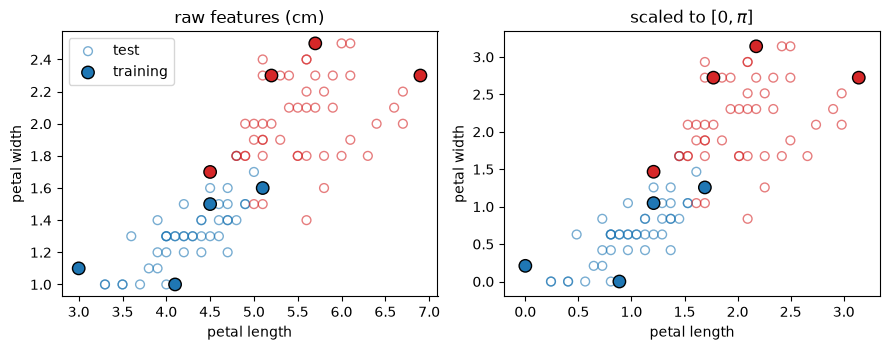

raw    range per feature: [3. 1.] to [6.9 2.5]
scaled range per feature: [0. 0.] to [3.142 3.142]
test values outside the training range: 0


In [3]:
X_train, X_test = minmax_scale(X_raw, X_test_raw)

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.6))

colors = ["tab:blue" if label < 0 else "tab:red" for label in np.asarray(y_train)]
test_colors = ["tab:blue" if label < 0 else "tab:red" for label in np.asarray(y_test)]

for axes, train_points, test_points in [(left, X_raw, X_test_raw), (right, X_train, X_test)]:
    axes.scatter(
        test_points[:, 0], test_points[:, 1], facecolors="none", edgecolors=test_colors, s=40, alpha=0.6, label="test"
    )
    axes.scatter(train_points[:, 0], train_points[:, 1], c=colors, s=80, edgecolors="black", label="training")
    axes.set_xlabel("petal length")
    axes.set_ylabel("petal width")

left.set_title("raw features (cm)")
left.legend()
right.set_title("scaled to $[0, \\pi]$")
for axis in (right.set_xlim, right.set_ylim):
    axis(-0.2, np.pi + 0.2)

fig.tight_layout()
plt.show()

print("raw    range per feature:", X_raw.min(axis=0), "to", X_raw.max(axis=0))
print("scaled range per feature:", np.round(X_train.min(axis=0), 3), "to", np.round(X_train.max(axis=0), 3))
print("test values outside the training range:", int(np.sum((X_test_raw < X_raw.min(axis=0)) | (X_test_raw > X_raw.max(axis=0)))))

# The scaled features go on to the quantum side and are handed over as jax arrays.
X_train = jnp.asarray(X_train)
X_test = jnp.asarray(X_test)

Scaling stretches each axis by its own factor, and the cloud of points changes shape. A straight line stays a straight line, though, which keeps the species as separable as before, and every value is now a usable rotation angle. Still, the two species overlap. One versicolor and one virginica both have petals 4.8 cm long and 1.8 cm wide, which means no classifier can get every flower right.

Two further helpers cover the input requirements of the other encodings. `normalize` scales each sample to unit norm. `Encoding.amplitude` needs this. `binarize` reduces features to the 0/1 values that `Encoding.basis` works in.

In [4]:
print("normalize :", np.round(normalize(np.array([[3.0, 4.0]])), 3), " (norm 5 -> 1)")
print("binarize  :", binarize(np.array([[0.8, -0.2, 1.5]])))

normalize : [[0.6 0.8]]  (norm 5 -> 1)
binarize  : [[1 0 1]]


## Encoding

A quantum circuit cannot read numbers. It always starts from the same state, which in our two-qubit case is $\ket{00}$, and data can only get in through gates whose settings depend on the data. How we choose those gates is the **encoding**, and it matters more than it first appears. Everything the model computes afterwards starts from the encoded state, which means the encoding decides what the model *can* learn. Two flowers that encode to the same state, like the unscaled petals above, can never be told apart, whatever the ansatz does. The encoding also fixes which *kind* of function of the features the model can produce.

### Angle encoding

`Encoding.angle` writes each feature into the rotation angle of one qubit. A register of $n$ qubits therefore holds $n$ features. To see what that means, start with a single qubit. The rotation $R_Y(\theta)$ turns $\ket{0}$ into

$$R_Y(\theta)\ket{0} = \cos(\theta/2)\ket{0} + \sin(\theta/2)\ket{1}.$$

The two numbers in front of $\ket{0}$ and $\ket{1}$ are amplitudes. Squared, they give the probabilities of measuring $0$ and $1$. At $\theta = 0$ the qubit stays $\ket{0}$. At $\theta = \pi$, $\cos(\pi/2) = 0$ and $\sin(\pi/2) = 1$, and the qubit is in $\ket{1}$. In between, the probability of measuring $1$, $\sin^2(\theta/2)$, rises smoothly from $0$ to $1$. On the Bloch sphere, this is the state turning by $\theta$ from $\ket{0}$ at the top towards $\ket{1}$ at the bottom.

<p align="center"><img src="../../_static/qml_ry_rotation.svg" alt="A slice through the Bloch sphere with |0> at the top and |1> at the bottom. The state R_Y(theta)|0> points at angle theta from the top. Its height is <Z> = cos(theta). Theta = 0 gives |0>, theta = pi/2 an equal superposition, theta = pi gives |1>. The state is cos(theta/2)|0> + sin(theta/2)|1>, and the probability of measuring 1 is sin^2(theta/2)." width="640"></p>

Angle encoding uses each feature as an angle, rotating qubit $0$ by $x_0$ and qubit $1$ by $x_1$. The two qubits are rotated independently, which means the register holds the two one-qubit states side by side, written with $\otimes$

$$\big(\cos(x_0/2)\ket{0} + \sin(x_0/2)\ket{1}\big) \otimes \big(\cos(x_1/2)\ket{0} + \sin(x_1/2)\ket{1}\big).$$

The symbol $\otimes$ (the tensor product) means "qubit $0$ in this state, qubit $1$ in that one". Multiplying it out like ordinary brackets gives one term for every combination of the two qubits. Each term multiplies the amplitudes of the two qubits. Writing qubit $0$ first in each ket gives

$$\cos\tfrac{x_0}{2}\cos\tfrac{x_1}{2}\,\ket{00} + \cos\tfrac{x_0}{2}\sin\tfrac{x_1}{2}\,\ket{01} + \sin\tfrac{x_0}{2}\cos\tfrac{x_1}{2}\,\ket{10} + \sin\tfrac{x_0}{2}\sin\tfrac{x_1}{2}\,\ket{11}.$$

Squaring an amplitude again gives the probability of that outcome. The system is in state $\ket{11}$, with both qubits reading $1$, with probability $\sin^2(x_0/2)\,\sin^2(x_1/2)$. This is the product of the two single-qubit probabilities. Up to here, each qubit carries its own feature independently.

The smallest training value now lands on $\ket{0}$ and the largest on $\ket{1}$. Every value in between gets its own state, and nothing wraps round. This is why we scaled into $[0, \pi]$. After scaling, versicolor with its smaller petals sits towards $\ket{00}$. Virginica sits towards $\ket{11}$.

### Other encodings

Angle encoding is the simplest choice, and there are others. `qrisp.qml` provides four encodings. They trade the number of qubits against the cost of the circuit and against what they keep of the data.

| Encoding | Features on $n$ qubits | How a feature enters | What it needs |
|---|---|---|---|
| `Encoding.angle` | $n$ | one rotation per qubit | features scaled to angles |
| `Encoding.dense_angle` | $2n$ | a rotation and a relative phase per qubit | features scaled to angles |
| `Encoding.amplitude` | $2^n$ | as the amplitudes of the whole register | unit length, which it enforces itself. Only the direction of the feature vector survives. |
| `Encoding.basis` | $n$ | each qubit set to $0$ or $1$ | bits, and other values are reduced to bits |

Packing more features into fewer qubits has a cost. Amplitude encoding fits exponentially many features, but preparing an arbitrary state takes a deep circuit, around two orders of magnitude slower per call than angle encoding. Basis encoding suits data that really is binary and loses everything else, and with the default threshold every petal length becomes $1$. Dense angle encoding halves the qubit count, at the price of two features sharing one qubit.

For two features on two qubits, angle encoding is the natural choice, with one cheap rotation per feature and a state we can reason about directly. We try `dense_angle` later in this tutorial. At the end of this section we look at what `amplitude` does to a feature vector.

### Further reading

M. Schuld and F. Petruccione, [*Machine Learning with Quantum Computers*](https://doi.org/10.1007/978-3-030-83098-4), 2nd ed., Springer (2021), is the standard textbook on the field and covers how classical data is encoded into quantum states. R. LaRose and B. Coyle, [*Robust data encodings for quantum classifiers*](https://doi.org/10.1103/PhysRevA.102.032420), Phys. Rev. A **102**, 032420 (2020) ([arXiv:2003.01695](https://arxiv.org/abs/2003.01695)), defines angle, dense angle and amplitude encoding, the last of which it calls wavefunction encoding, and shows that the encoding decides which decision boundaries a classifier can learn. M. Schuld, R. Sweke and J. J. Meyer, [*Effect of data encoding on the expressive power of variational quantum machine learning models*](https://doi.org/10.1103/PhysRevA.103.032430), Phys. Rev. A **103**, 032430 (2021) ([arXiv:2008.08605](https://arxiv.org/abs/2008.08605)), explains why the encoding fixes the kind of function that a model can express, and how encoding the data more than once, known as data re-uploading, widens it.

Let us encode three of our training flowers. They are the shortest versicolor, the longest versicolor and the longest virginica. For each one we print the probability of every outcome when both qubits are measured.

Qrisp prints a register as a number rather than as a string of bits, with qubit $0$ as the lowest bit. $\ket{00}$ appears as `|0>` and $\ket{11}$ as `|3>`. The small helper below converts the outcomes back into bits, written with qubit $0$ first as in the formula above. It keeps Qrisp's order. `10` comes before `01`, as in the bar charts further down.

In [5]:
encoding = Encoding.angle(n_features=2)


def outcome_probabilities(qf):
    # Qrisp reports the register as a number with qubit 0 as the lowest bit.
    # We spell it out with qubit 0 first.
    return {f"{int(v) & 1}{int(v) >> 1}": round(float(p), 3) for v, p in sorted(qf.get_measurement().items())}


for name, i in [("shortest versicolor", 0), ("longest versicolor", 3), ("longest virginica", 7)]:
    qf = QuantumFloat(2)
    encoding.apply(qf, X_train[i])
    print(f"{name:20s} features {np.round(np.asarray(X_train[i]), 2)} -> {outcome_probabilities(qf)}")

shortest versicolor  features [0.   0.21] -> {'00': 0.989, '01': 0.011}


longest versicolor   features [1.69 1.26] -> {'00': 0.288, '10': 0.367, '01': 0.152, '11': 0.194}


longest virginica    features [3.14 2.72] -> {'10': 0.043, '11': 0.957}


Each qubit holds one feature, with the petal length on qubit $0$ and the petal width on qubit $1$. A measured $1$ on a qubit loosely means "long" or "wide", and it becomes more likely the further along its scaled range the feature sits, with probability $\sin^2(x_i/2)$. `00` therefore reads as short and narrow, and `11` as long and wide. Because the two qubits are encoded independently, each outcome's probability is the product of the two single-qubit probabilities.

The shortest versicolor sits at the bottom of both ranges and gives `00` almost every time. The longest virginica sits at the top and gives `11`. The longest versicolor lies in the middle of both ranges, where the species overlap, and its outcomes are spread across all four.

Each qubit on its own is a slice through its Bloch sphere, exactly as in the single-qubit figure above. The arrow sits at the angle of its feature. Its probability of reading $1$ grows as it turns from $\ket{0}$ towards $\ket{1}$. This one-picture-per-qubit view works only while the qubits are independent, as they are right after encoding. Once the ansatz entangles them, a qubit no longer has a state of its own.

<p align="center"><img src="../../_static/qml_encoding_bloch.svg" alt="Three rows, one per flower. Each row has two Bloch-circle slices, qubit 0 for petal length and qubit 1 for petal width. Row A is the shortest versicolor. Both arrows point near |0>, with x0 = 0 (P(1) = 0%) and x1 = 0.21 (P(1) = 1%). Row B is the longest versicolor, with x0 = 1.69 (P(1) = 56%) and x1 = 1.26 (P(1) = 35%). Both arrows are near the equator. Row C is the longest virginica, with x0 = pi (P(1) = 100%) and x1 = 2.72 (P(1) = 96%). Both arrows are near |1>. A bar chart beside each row gives the probabilities of the four outcomes when both qubits are measured. A gives 99% 00 and 1% 01. B gives 29% 00, 37% 10, 15% 01 and 19% 11. C gives 96% 11 and 4% 10." width="800"></p>

The bar charts on the right show what happens when both qubits are measured together. Each outcome's probability is the product of the two qubits' own probabilities. Flower B, for example, gives `10`, long and narrow, with probability $0.56 \times 0.65 \approx 0.37$.

### A look at amplitude encoding

`Encoding.amplitude` writes the features into the *amplitudes* of the register rather than into rotation angles. A register of $n$ qubits holds $2^n$ amplitudes. It encodes exponentially more features per qubit than angle encoding. It fits 4 features on 2 qubits and 1024 on 10.

Two consequences follow from a quantum state having unit norm. The feature vector is normalized internally, which means only its *direction* is encoded and its length is lost. And the vector is zero-padded up to the size of the register, since a register holds a power of two amplitudes while feature vectors rarely do.

In [20]:
qf = QuantumFloat(2)
Encoding.amplitude(n_features=3).apply(qf, [1.0, 2.0, 3.0])

# Padded to (1, 2, 3, 0), then normalized by sqrt(14).
# Adding 0.0 turns a rounded -0.0 into 0.0.
print("amplitudes:", np.round(np.array(qf.qs.statevector("array")).real, 4) + 0.0)
print("expected  :", np.round(np.array([1, 2, 3, 0]) / np.sqrt(14), 4))

amplitudes: [0.2673 0.8018 0.5345 0.    ]
expected  : [0.2673 0.5345 0.8018 0.    ]


`statevector("array")` is indexed in reverse bit order. The amplitude of $\ket{i}$ is not at index $i$ of that array. That is why the two rows above agree only up to that reordering.

## Ansatz

The encoding gives the model no freedom, since the same flower always becomes the same state. To learn, the circuit also needs settings we can change. That is the job of the **ansatz**, a circuit whose rotation angles are the model's parameters $\underline{w}$. During training, the optimizer adjusts these angles, much like the weights of a neural network. `Ansatz.real_amplitudes` alternates layers of $R_Y$ rotations with CX entanglers.

$$R_Y(\underline{w}^{(L)})\, U_{\text{ent}} \cdots R_Y(\underline{w}^{(1)})\, U_{\text{ent}}\, R_Y(\underline{w}^{(0)})$$

As usual for operators, the product acts from right to left. $R_Y(\underline{w}^{(0)})$ is applied first. Here $R_Y(\underline{w}^{(l)})$ is one layer of rotations, one per qubit, whose angles are the part $\underline{w}^{(l)}$ of the parameter vector. In the figure below, the first layer has the angles $w_0$ and $w_1$. The second has $w_2$ and $w_3$.

There is one more rotation layer than entangling layers. The output of the last entangler is rotated before it is measured.

Here is the circuit we build, with the encoding and the ansatz marked.

<p align="center"><img src="../../_static/qml_circuit.svg" alt="The two-qubit circuit. Both qubits start in |0>. The encoding S(x), marked in green, rotates qubit 0 by R_Y(x0) and qubit 1 by R_Y(x1), using the features x = (x0, x1), and produces the state |psi(x)>. The ansatz W(w), marked in blue, applies R_Y(w0) and R_Y(w1), a CX gate with qubit 0 as control and qubit 1 as target, then R_Y(w2) and R_Y(w3), and produces the state |psi(x, w)>." width="560"></p>

Every ansatz has a companion size function giving the number of parameters it needs. We use it rather than working the count out by hand, because it keeps the parameter vector correct when the register size or layer count changes.

Below we build the ansatz, apply it with untrained parameters to just one sample after encoding it, and print the circuit Qrisp has built. The two encoding rotations come first. The ansatz follows.

In [6]:
num_qubits = 2
layers = 1
num_params = real_amplitudes_size(num_qubits, layers=layers)
ansatz = Ansatz.real_amplitudes(num_qubits=num_qubits, layers=layers)
print(f"{num_qubits} qubits, {layers} layer(s) -> {num_params} parameters\n")

# Untrained parameters. Each one is distinct, which makes its gate's angle visible in the drawing.
w_example = jnp.array([0.5, 1.0, 1.5, 2.0])

qf = QuantumFloat(num_qubits)
encoding.apply(qf, X_train[0])
ansatz.apply(qf, w_example)
print(qf.qs)

2 qubits, 1 layer(s) -> 4 parameters



QuantumCircuit:
---------------
       ┌───────┐  ┌─────────┐     ┌─────────┐
qf.0: ─┤ Ry(0) ├──┤ Ry(0.5) ├──■──┤ Ry(1.5) ├
      ┌┴───────┴─┐└┬───────┬┘┌─┴─┐└┬───────┬┘
qf.1: ┤ Ry(π/15) ├─┤ Ry(1) ├─┤ X ├─┤ Ry(2) ├─
      └──────────┘ └───────┘ └───┘ └───────┘ 
Live QuantumVariables:
----------------------
QuantumFloat qf


## Measurement

To get a prediction out of the circuit, we measure it. A measurement is always made along some axis, and the usual choice, which is ours here, is the $Z$ axis. Measured along $Z$, a qubit gives one of two outcomes, $\ket{0}$ or $\ket{1}$. A single measurement tells us very little, which is why we prepare and measure the circuit many times and count how often each outcome appears. This gives the probability distribution of the outcomes. (It is not the full state, since phases, for example, do not show up in these counts.)

For a classifier we want a single number, and we score each outcome to get one, with $+1$ for $\ket{0}$ and $-1$ for $\ket{1}$, which matches the $\pm 1$ labels. The average score over many runs is the **expectation value** $\langle Z_0 \rangle$, which in code we ask for with the observable `Z(0)`. The function `expectation`, provided by the `qrisp.qml` module, does the repeated measuring and averaging for us. Because it has to run the circuit many times, we pass it a function that builds the circuit, `prepare` below, rather than a circuit that has already been built.

We read out qubit 0 alone. Angle encoding needs two qubits to hold the two features, though an encoding such as `Encoding.dense_angle`, which we try later, could fit both into one. A binary classifier needs only one output number either way. Qubit 1 still influences the prediction. The CX gate entangles the two qubits, and the final rotation $R_Y(w_2)$ on qubit 0 turns that entanglement into a change in $\langle Z_0 \rangle$. The flip side is that a gate on qubit 1 *after* the CX can no longer reach the measured qubit. The last rotation $R_Y(w_3)$ has no effect on the prediction. With this readout, only three of the four parameters matter. Whenever part of a register is left unmeasured, it is worth checking which gates can still affect what is read out.

Below we read out $\langle Z_0 \rangle$ for the encoded flower from the previous cell. `precision` sets how tightly each expectation value is estimated. The shot count scales with the inverse square of it. `0.05` is far cheaper than the default `0.01` and accurate enough while iterating.

In [7]:
def prepare():
    qf = QuantumFloat(num_qubits)
    encoding.apply(qf, X_train[0])
    ansatz.apply(qf, w_example)
    return qf


value = expectation(prepare, Z(0), precision=0.05)()
print(f"Sample 0 (shortest versicolor), untrained parameters: <Z_0> = {float(value):+.3f}")

Sample 0 (shortest versicolor), untrained parameters: <Z_0> = -0.368


## The model

The model is made up of the encoding, the ansatz and the measurement. It is a function that takes a flower's features $\underline{x}$ and the parameters $\underline{w}$ and returns a prediction. Up to now we ran each stage by hand on a single flower. The functions `circuit` and `model` below package the same three steps. We can then apply them to any flower. Training needs this.

With untrained parameters, the model gives a versicolor and a virginica almost the same output. It does not yet tell the species apart. Each output is estimated from a finite number of measurements. With `precision=0.05` it varies by a few hundredths from one run to the next. That is also why the shortest versicolor need not give exactly the value printed above. Finding parameters that push versicolor towards $-1$ and virginica towards $+1$ is the job of training.

In [8]:
def circuit(x, w):
    qf = QuantumFloat(num_qubits)
    encoding.apply(qf, x)
    ansatz.apply(qf, w)
    return qf


def model(x, w):
    return expectation(lambda: circuit(x, w), Z(0), precision=0.05)()


for name, i in [("shortest versicolor", 0), ("longest virginica", 7)]:
    print(f"{name:20s} label {float(y_train[i]):+.0f}  ->  untrained prediction {float(model(X_train[i], w_example)):+.3f}")

shortest versicolor  label -1  ->  untrained prediction -0.338


longest virginica    label +1  ->  untrained prediction -0.338


## Loss and training

For the loss we use the mean squared error between predictions and labels. It takes only the parameters, which is the signature `minimize` expects. `make_loss` builds that function for a given model and dataset. We reuse it with the other models later on.

`minimize` is **gradient-free**. It samples the loss rather than differentiating it, because the expectation values come from sampling and carry no derivative. Tracing a circuit with Jasp makes it fast, because the circuit is built once and then reused instead of being rebuilt in Python for every evaluation, but it does not make it differentiable. Gradients can still be obtained from extra circuit runs with the parameter-shift rule. The [transfer learning tutorial](QMLTransferLearning.ipynb) trains a model that way.

In [9]:
def make_loss(model_fn, X, y):
    def loss(w):
        total = 0.0
        for i in range(X.shape[0]):
            total = total + jnp.sum((model_fn(X[i], w) - y[i]) ** 2)
        return total / X.shape[0]

    return loss

We run training inside `@jaspify`. Jasp owns the outermost layer of a hybrid program, which means quantum and classical code compose freely *inside* it, while it cannot be nested inside `jax.jit` from the outside.

The optimizer is **local** and descends from its starting point into the nearest minimum. A run that stalls at a poor loss usually means the starting point was bad, rather than that the model cannot fit the data. In practice one trains from several starting points and keeps the best. Here we keep things simple and use a single starting point.

`minimize` only returns the final result. We want to watch training as it happens. The loss therefore reports every value it computes, using `jax.debug.callback`. A plot is redrawn after each iteration of the optimizer. It shows the lowest loss among the parameter values the optimizer keeps.

We set `maxiter` to 20. Internally `minimize` keeps a step size called `rho`, which starts at $1$ and halves every iteration, and it stops once `rho` falls below a tolerance, `rhoend` $= 10^{-6}$. After 20 halvings, $2^{-20} \approx 9.5 \times 10^{-7}$ is below that tolerance. `minimize` does not document either default, which is why we leave them alone, and with them a larger `maxiter` would not train any longer.

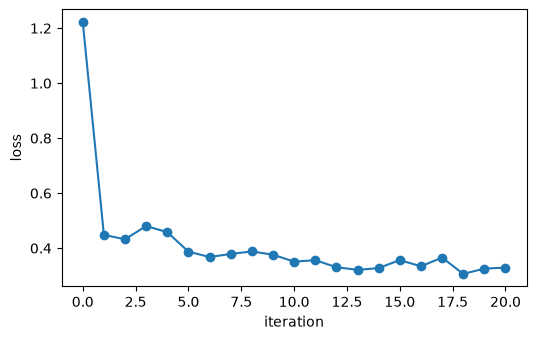

loss 1.223 -> 0.359 after 20 iterations


In [10]:
best_per_iteration = []
evaluations = []


def record_loss(value):
    evaluations.append(float(value))
    # The optimizer first computes the loss at num_params + 1 points.
    # It then computes it num_params + 4 more times per iteration.
    # The last num_params + 1 values of an iteration are the points it keeps.
    computed_after_start = len(evaluations) - (num_params + 1)
    if computed_after_start >= 0 and computed_after_start % (num_params + 4) == 0:
        best_per_iteration.append(min(evaluations[-(num_params + 1) :]))
        clear_output(wait=True)
        plt.figure(figsize=(6, 3.6))
        plt.plot(best_per_iteration, marker="o")
        plt.xlabel("iteration")
        plt.ylabel("loss")
        plt.show()


loss = make_loss(model, X_train, y_train)


def loss_with_plot(w):
    value = loss(w)
    jax.debug.callback(record_loss, value)
    return value


@jaspify(terminal_sampling=True)
def train():
    w0 = jnp.array([1.5] * num_params)
    result = minimize(loss_with_plot, w0, method="COBYLA", options={"maxiter": 20})
    return result.x, result.fun


w_opt, final_loss = train()
print(f"loss {best_per_iteration[0]:.3f} -> {float(final_loss):.3f} after {len(best_per_iteration) - 1} iterations")

## Checking the predictions

A low loss should show in the predictions themselves. We check them on the test set as well as the training set. For a $\pm 1$ classifier the sign is what matters.

The training accuracy may come out *lower* than the test accuracy. We picked the training flowers to span each species from its shortest petal to its longest. The training set therefore contains the hardest cases on purpose. The longest-petalled versicolor (5.1 cm) sits inside the range of virginica. The shortest-petalled virginica (4.5 cm) sits inside the range of versicolor. A boundary that suits the rest of the data is likely to misclassify both. There are only eight training flowers. Missing those two alone costs 25%. In the test set, the flowers from the overlap are a small share among many typical ones. Its accuracy is therefore the better measure of the model.

In [11]:
@jaspify(terminal_sampling=True)
def predict(X):
    return jnp.array([model(X[i], w_opt) for i in range(X.shape[0])])


for name, features, targets in [("training", X_train, y_train), ("test", X_test, y_test)]:
    correct = np.sign(np.asarray(predict(features))) == np.sign(np.asarray(targets))
    print(f"{name:8s} accuracy: {np.mean(correct):.3f}  ({int(np.sum(~correct))} of {len(correct)} misclassified)")

training accuracy: 0.875  (1 of 8 misclassified)


test     accuracy: 0.957  (4 of 92 misclassified)


### The decision boundary

To see what the model has learned, we evaluate it on the flowers and on a grid of points covering the whole square of scaled features, with petal length across and petal width up. At every grid point, the background colour shows the model's output $\langle Z_0 \rangle$ for a flower with those features.

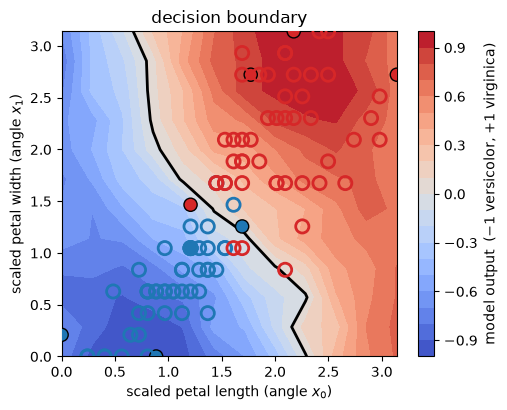

In [12]:
resolution = 12
grid_axis = np.linspace(0.0, np.pi, resolution)
grid = jnp.array([[a, b] for b in grid_axis for a in grid_axis])


@jaspify(terminal_sampling=True)
def predict_grid():
    return jnp.array([model(grid[i], w_opt) for i in range(grid.shape[0])])


surface = np.asarray(predict_grid()).reshape(resolution, resolution)

plt.figure(figsize=(5.2, 4.2))
plt.contourf(grid_axis, grid_axis, surface, levels=20, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="model output  (−1 versicolor, +1 virginica)")
plt.contour(grid_axis, grid_axis, surface, levels=[0.0], colors="black", linewidths=2)

training = np.asarray(X_train)
testing = np.asarray(X_test)
plt.scatter(training[:, 0], training[:, 1], c=colors, s=90, edgecolors="black", zorder=3)
plt.scatter(testing[:, 0], testing[:, 1], facecolors="none", edgecolors=test_colors, s=90, linewidths=2, zorder=3)
plt.xlabel("scaled petal length (angle $x_0$)")
plt.ylabel("scaled petal width (angle $x_1$)")
plt.title("decision boundary")
plt.tight_layout()
plt.show()

Here is how to read the plot.

- The background colour shows the model's output for a flower with those two features, read off the colour bar. Deep blue, close to $-1$, means the model says versicolor, deep red, close to $+1$, means virginica, and in the pale band in between the model is unsure.
- The black line is where the output crosses $0$. This is the **decision boundary**, with everything on the blue side called versicolor and everything on the red side virginica.
- The dots are the real flowers, coloured by their *true* species, blue for versicolor and red for virginica. Filled dots are the eight training flowers, and hollow dots are the test flowers.
- A dot on the wrong side of the line is misclassified. A red dot on the blue side is a virginica that the model calls versicolor, and a blue dot on the red side is the reverse. Most misclassified dots sit close to the line, where the two species overlap.

Two details. The line looks jagged only because the grid is coarse, with $12 \times 12$ points, and each output is a sampled estimate, while the actual output of the model is a smooth function of the features. The dots on the edges of the square are flowers with the smallest or largest value of a feature in the training data.

## What we have built

That completes the pipeline from the figure at the top. We started from flower measurements in centimetres, scaled them into rotation angles and encoded each flower into a two-qubit state. A trainable ansatz transformed that state, and we read out one number, $\langle Z_0 \rangle$, whose sign is the prediction. Training adjusted the parameters $\underline{w}$ until those predictions matched the labels of eight flowers, and the trained model classifies most of the test flowers correctly, although it never saw them during training.

## Saving and reusing the model

A trained model is made up of the circuit, which is code, and the numbers that training produced. `save_model` from `qrisp.qml` stores the parts of a model in a file, each under a name that we choose, and `load_model` returns them under the same names. We save four parts, the encoding, the ansatz, the observable and the trained parameters.

For the encoding, we save one that does the scaling itself. We give it the range of each feature in the training data through `data_range`. It then scales raw measurements exactly as `minmax_scale` did. This includes clipping values outside that range. The saved model therefore takes flower measurements directly in centimetres.

In [13]:
model_file = Path(tempfile.gettempdir()) / "iris_model.pkl"
save_model(
    model_file,
    encoding=Encoding.angle(n_features=2, data_range=(X_raw.min(axis=0), X_raw.max(axis=0))),
    ansatz=ansatz,
    observable=Z(0),
    parameters=w_opt,
)

In a new session, we load the parts and put the circuit together exactly as before. A model file can run code when it is loaded. Any format based on Python's pickle can do this. Only load files from a source you trust. Below we classify two new flowers that are not in the dataset.

In [14]:
saved = load_model(model_file)


def loaded_model(x_cm):
    def prepare():
        qf = QuantumFloat(num_qubits)
        saved["encoding"].apply(qf, x_cm)
        saved["ansatz"].apply(qf, saved["parameters"])
        return qf

    return expectation(prepare, saved["observable"], precision=0.05)()


# Two new flowers, as (petal length, petal width) in centimetres.
new_flowers = jnp.array([[4.0, 1.2], [6.0, 2.2]])


@jaspify(terminal_sampling=True)
def predict_new():
    return jnp.array([loaded_model(new_flowers[i]) for i in range(new_flowers.shape[0])])


for flower, output in zip(np.asarray(new_flowers), np.asarray(predict_new())):
    species = "virginica" if output > 0 else "versicolor"
    print(f"petal {flower[0]} cm by {flower[1]} cm -> output {output:+.2f} -> {species}")

petal 4.0 cm by 1.2 cm -> output -0.89 -> versicolor
petal 6.0 cm by 2.2 cm -> output +0.96 -> virginica


The circuit itself can also be written out in OpenQASM 3. OpenQASM 3 is a standard format that other quantum software reads. Here it is for the first new flower, with its encoded angles and the trained parameters filled in.

In [15]:
qf = QuantumFloat(num_qubits)
saved["encoding"].apply(qf, new_flowers[0])
saved["ansatz"].apply(qf, saved["parameters"])
print(qf.qs.compile().to_qasm3())

OPENQASM 3.0;
include "stdgates.inc";
qubit[1] _qf_0;
qubit[1] _qf_1;
ry(0.8718586969169841) _qf_0[0];
ry(2.136983274963481) _qf_1[0];
cx _qf_0[0], _qf_1[0];
ry(2.343239585302854) _qf_0[0];
ry(2.011276954377081) _qf_1[0];



## Swapping the parts

The model we saved has four parts, an encoding, an ansatz, an observable and the trained parameters. Each one is a separate object, which means we can replace one part and keep the rest. We start from the model we loaded, `saved`, and change one part at a time. In the figure for each change, grey marks what we keep from the saved model and orange marks what is new.

A changed model has to be trained again. Training does not always have to start from scratch, though. The new model may still contain the old one. The trained parameters are then a much better starting point than any fixed value.

The helper `make_model` builds a model from any encoding, ansatz and observable, in the same way as `loaded_model` above. `train_from` trains a model from a given starting point and returns the loss before and after training, together with the trained parameters. If we pass it a list as `history`, it also records every loss value it computes. `plot_losses` then plots the loss of one or more runs per iteration, as in the training section, and marks the loss at the starting point with a hollow circle. Since the saved encoding does its own scaling, we train on the measurements in centimetres.

In [16]:
def make_model(encoding, ansatz, observable):
    def model_fn(x, w):
        def prepare():
            qf = QuantumFloat(num_qubits)
            encoding.apply(qf, x)
            ansatz.apply(qf, w)
            return qf

        return expectation(prepare, observable, precision=0.05)()

    return model_fn


def train_from(model_fn, X, y, w0, history=None):
    if history is None:
        history = []
    loss = make_loss(model_fn, X, y)

    def tracked_loss(w):
        value = loss(w)
        jax.debug.callback(lambda v: history.append(float(v)), value)
        return value

    @jaspify(terminal_sampling=True)
    def run():
        result = minimize(tracked_loss, w0, method="COBYLA", options={"maxiter": 20})
        return result.fun, result.x

    final_loss, w = run()
    # The optimizer computes the loss at the starting point first.
    return history[0], final_loss, w


def loss_per_iteration(evaluations, n):
    # The same bookkeeping as the live plot. There are n + 1 starting points, then n + 4 evaluations
    # per iteration. The last n + 1 of them are the points the optimizer keeps.
    return [min(evaluations[end - n - 1 : end]) for end in range(n + 1, len(evaluations) + 1, n + 4)]


def plot_losses(runs):
    # runs is a list of (label, recorded loss values, number of parameters).
    plt.figure(figsize=(6, 3.6))
    for label, evaluations, n in runs:
        line = plt.plot(loss_per_iteration(evaluations, n), marker="o", label=label)[0]
        # The optimizer computes the loss at the starting point first.
        plt.plot(0, evaluations[0], marker="o", markersize=10, fillstyle="none", color=line.get_color())
    plt.ylim(bottom=0)
    plt.xlabel("iteration")
    plt.ylabel("loss")
    plt.legend()
    plt.show()


X_cm, X_test_cm = jnp.asarray(X_raw), jnp.asarray(X_test_raw)

### A different ansatz

`Ansatz.hardware_efficient` takes the rotation axes as an argument. With `("y", "z")`, each qubit gets an $R_Y$ and then an $R_Z$ rotation in every layer. This doubles the parameters of `Ansatz.real_amplitudes`. It also gives the model access to complex amplitudes rather than only real ones.

<p align="center"><img src="../../_static/qml_swap_ansatz.svg" alt="The saved circuit with its ansatz replaced. The encoding R_Y(x0), R_Y(x1) and the readout Z0 are grey and kept from the saved model. The ansatz is orange and new. Each qubit gets R_Y then R_Z, then a CX, then R_Y then R_Z again. The R_Y gates are grey and carry the trained angles w0 to w3. The R_Z gates are orange and start at angle 0." width="720"></p>

The new ansatz contains the old one. Since $R_Z(0)$ does nothing, giving the $R_Y$ gates the trained angles and setting every $R_Z$ angle to $0$ makes the new model compute exactly what the saved one did. Training then starts from the trained model, and the best loss that the new model can reach is at least as low as the old one's. Whether training finds a lower one is another matter. In the parameter vector, each layer lists its $R_Y$ angles for both qubits first and then its $R_Z$ angles, which puts the trained $w_0, w_1$ at positions 0 and 1, and $w_2, w_3$ at positions 4 and 5.

We want to see what this gains us. We therefore also train the same model from our usual starting point, with every angle at 1.5. We plot the loss of both runs per iteration.

from the trained angles  loss 0.367 -> 0.363


from 1.5                 loss 1.028 -> 1.021


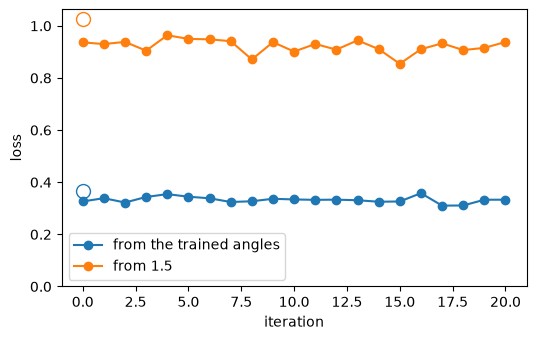

In [17]:
ansatz_he = Ansatz.hardware_efficient(num_qubits=num_qubits, layers=1, rotations=("y", "z"))
model_he = make_model(saved["encoding"], ansatz_he, saved["observable"])

w = saved["parameters"]
w_reused = jnp.array([w[0], w[1], 0.0, 0.0, w[2], w[3], 0.0, 0.0])
w_fresh = jnp.array([1.5] * hardware_efficient_size(num_qubits, layers=1, rotations=("y", "z")))

runs = []
for name, w0 in [("from the trained angles", w_reused), ("from 1.5", w_fresh)]:
    history = []
    start, end, _ = train_from(model_he, X_cm, y_train, w0, history=history)
    print(f"{name:24s} loss {float(start):.3f} -> {float(end):.3f}")
    runs.append((name, history, len(w0)))

plot_losses(runs)

Started from the trained angles, the new model begins at about the loss that the saved model reached and stays there, which means the extra rotations add little for this data. Started from 1.5, the same model stays at a much higher loss. It can represent the better solution, but the optimizer only searches near its starting point and does not find it. The small ups and downs in both curves come from sampling, since every loss value is estimated from measurements.

### A different encoding

`Encoding.dense_angle` packs *two* features per qubit, one as a rotation angle and one as a relative phase, which lets two qubits carry four features instead of two. We keep the register the same size while giving the model all four Iris measurements, sepals as well as petals. Like the saved encoding, it does its own scaling, here from the range of all four measurements in the training data.

<p align="center"><img src="../../_static/qml_swap_encoding.svg" alt="The saved circuit with its encoding replaced. The encoding is orange and new. Qubit 0 gets R_Y(x0) and a phase P(x1). Qubit 1 gets R_Y(x2) and P(x3). Here x0 and x1 are sepal length and width, and x2 and x3 are petal length and width. The ansatz R_Y(w0), R_Y(w1), CX, R_Y(w2), R_Y(w3) and the readout Z0 are grey. They are kept, but the ansatz parameters start again." width="720"></p>

This time the trained parameters are of little use. They were tuned for petal length on qubit 0 and petal width on qubit 1, while qubit 0 now carries the sepal measurements and the petal width enters as a phase. The number of parameters still matches, which means the code would accept them, but nothing makes them suited to the new input. We start again from 1.5.

dense_angle, 4 features on 2 qubits: loss 1.397 -> 0.490


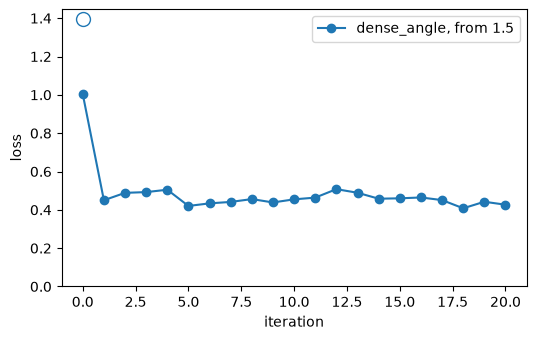

In [18]:
X4_cm = measurements[train_idx]
encoding_dense = Encoding.dense_angle(n_features=4, data_range=(X4_cm.min(axis=0), X4_cm.max(axis=0)))
model_dense = make_model(encoding_dense, saved["ansatz"], saved["observable"])

dense_history = []
w0 = jnp.array([1.5] * num_params)
start, end, _ = train_from(model_dense, jnp.asarray(X4_cm), y_train, w0, history=dense_history)
print(f"dense_angle, 4 features on {num_qubits} qubits: loss {float(start):.3f} -> {float(end):.3f}")
plot_losses([("dense_angle, from 1.5", dense_history, num_params)])

With all four measurements, the model ends at a higher loss than the saved model did with the two petal measurements. More features did not make a better model here. A likely reason is where they go. The measured qubit 0 now carries the two sepal measurements, which separate the species much less well than the petals, since a single cut sorts 73% and 63% of the flowers correctly, against 93 to 94% for the petals. The petal measurements sit on qubit 1 and reach the readout only through the CX gate.

### A different readout

We can pass a *list* of observables. `expectation` then returns one entry per observable instead of a single number. A model with several outputs is read out this way, for instance with one output per class. Here $\langle Z_0 \rangle$ keeps the meaning it was trained for, $+1$ for virginica. The new output $\langle Z_1 \rangle$ gives $+1$ for versicolor.

A summed operator such as `Z(0) + Z(1)` would instead collapse both qubits into a single number. The individual contributions cannot be recovered from that number.

<p align="center"><img src="../../_static/qml_swap_observable.svg" alt="The saved circuit with its readout replaced. The encoding and the ansatz, with its trained angles w0 to w3, are grey and kept. The readout is orange and new. Qubit 0 is measured for Z0, where +1 means virginica as trained. Qubit 1 is measured for Z1, where +1 means versicolor." width="720"></p>

The circuit is unchanged, which means the trained parameters fit it exactly and the first output is already trained. Starting from them, training has to bring the second output into line while keeping the first. We then check each output on the test set.

two observables: loss 3.018 -> 1.142


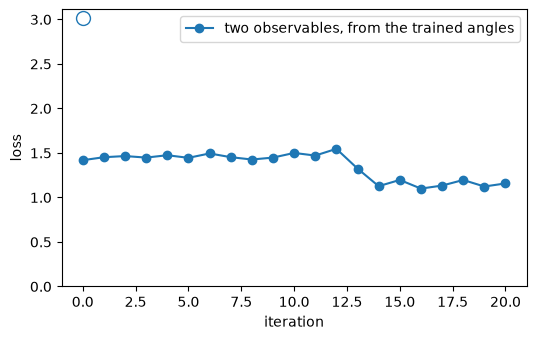

<Z_0> (+1 for virginica): test accuracy 0.848
<Z_1> (+1 for versicolor): test accuracy 0.761


In [19]:
# One output per species. Virginica is (+1, -1) and versicolor is (-1, +1).
y_two = jnp.stack([y_train, -y_train], axis=1)
model_two = make_model(saved["encoding"], saved["ansatz"], [Z(0), Z(1)])

two_history = []
start, end, w_two = train_from(model_two, X_cm, y_two, saved["parameters"], history=two_history)
print(f"two observables: loss {float(start):.3f} -> {float(end):.3f}")
plot_losses([("two observables, from the trained angles", two_history, num_params)])


@jaspify(terminal_sampling=True)
def predict_two():
    return jnp.array([model_two(X_test_cm[i], w_two) for i in range(X_test_cm.shape[0])])


outputs = np.asarray(predict_two())
for column, (observable, species, sign) in enumerate([("Z_0", "virginica", 1), ("Z_1", "versicolor", -1)]):
    accuracy = np.mean(np.sign(outputs[:, column]) == sign * np.asarray(y_test))
    print(f"<{observable}> (+1 for {species}): test accuracy {accuracy:.3f}")

The loss starts high only because $\langle Z_1 \rangle$ is not trained yet, while $\langle Z_0 \rangle$ starts where the saved model left it. Most of the drop happens right at the start, before the first iteration, because the optimizer first tries a step of size 1 in each parameter and one of these steps already moves $\langle Z_1 \rangle$ a long way towards its labels. After that, the loss changes little. The loss now adds up the errors of both outputs, which means it cannot be compared with the loss of the one-output model. After training, both outputs classify most of the test flowers correctly, but $\langle Z_0 \rangle$ does worse than it did alone. The same four parameters now have to serve two outputs, and what helps $\langle Z_1 \rangle$ can cost $\langle Z_0 \rangle$.

Whether the trained parameters can be reused depends on what changed. The circuit may be unchanged, as with the new readout. The new model may contain the old one, as with the larger ansatz. In both cases the trained parameters are the natural starting point. Training then carries on from what was already learned. The input to the circuit may change, as with the new encoding. The parameters were then tuned for different states, and we start again.

## A second optimizer

`minimize` offers two optimizers, COBYLA, which we have used up to now, and SPSA. Both work only with loss values, and neither needs a gradient from the circuit. COBYLA keeps a group of $n + 1$ points for $n$ parameters, five for our model, and uses the losses at these points to decide where to try next. At the end it returns the best point it has found. SPSA (Spall, 1992) follows a single point. Each step computes the loss at two points on either side of it, along a random direction, and moves towards the lower one. A step costs 2 loss evaluations however many parameters the model has, which makes SPSA suit models with many parameters and noisy losses like ours. It returns its last point.

A COBYLA iteration and an SPSA step cost different numbers of loss evaluations, and since loss evaluations are what takes the time, we compare the two by them. We train the main model with SPSA from the same starting point with 80 steps, which uses about as many loss evaluations as the 20 COBYLA iterations did. SPSA never computes the loss at its current point, only on either side of it, which is why we plot the average of each pair.

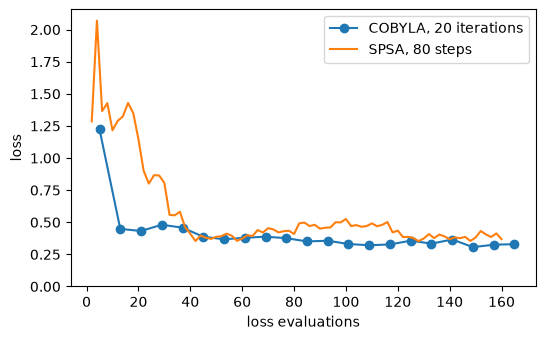

COBYLA: loss 1.223 -> 0.359 in 166 loss evaluations
SPSA:   loss 1.286 -> 0.352 in 161 loss evaluations


In [21]:
spsa_evaluations = []


def loss_spsa(w):
    value = loss(w)
    jax.debug.callback(lambda v: spsa_evaluations.append(float(v)), value)
    return value


@jaspify(terminal_sampling=True)
def train_spsa():
    result = minimize(loss_spsa, jnp.array([1.5] * num_params), method="SPSA", options={"maxiter": 80})
    return result.fun


spsa_final = float(train_spsa())

# Each step computes the loss on both sides of the current point. The last value is the final loss.
spsa_curve = [(a + b) / 2 for a, b in zip(spsa_evaluations[0:-1:2], spsa_evaluations[1:-1:2])]
spsa_counts = [2 * (k + 1) for k in range(len(spsa_curve))]
cobyla_counts = [num_params + 1 + k * (num_params + 4) for k in range(len(best_per_iteration))]

plt.figure(figsize=(6, 3.6))
plt.plot(cobyla_counts, best_per_iteration, marker="o", label="COBYLA, 20 iterations")
plt.plot(spsa_counts, spsa_curve, label="SPSA, 80 steps")
plt.ylim(bottom=0)
plt.xlabel("loss evaluations")
plt.ylabel("loss")
plt.legend()
plt.show()

print(f"COBYLA: loss {best_per_iteration[0]:.3f} -> {float(final_loss):.3f} in {len(evaluations)} loss evaluations")
print(f"SPSA:   loss {spsa_curve[0]:.3f} -> {spsa_final:.3f} in {len(spsa_evaluations)} loss evaluations")

With about the same number of loss evaluations, both optimizers end at a similar loss. They get there differently. The first trial points of COBYLA lie far apart, which makes its loss drop quickly at the start, and after that it improves slowly and steadily. SPSA takes its largest steps at the beginning, which can overshoot and briefly raise the loss, and its curve keeps wobbling, because every step relies on one random direction. The losses printed below the plot start from the first point of each curve, which for COBYLA is the lowest loss among its first five points and for SPSA the average of its first pair. Neither is exactly the loss at the starting point, which is why the two differ. The final losses are computed once more at the final parameters and can differ a little from the last point of each curve.

For a model as small as ours, either optimizer does the job. The difference grows with the number of parameters. COBYLA needs more loss evaluations with every parameter we add, starting with one for each of the $n + 1$ points of its group. An SPSA step always costs 2.

## Summary

We wrote the loss as an ordinary function and trained with a single call to `minimize`. The encoding and the ansatz are configured objects. Each is independent of the other. We could therefore swap every stage without touching the rest.

| Stage | Primitives |
|---|---|
| Preprocessing | `minmax_scale`, `normalize`, `binarize` |
| Encoding | `Encoding.angle`, `Encoding.dense_angle`, `Encoding.amplitude`, `Encoding.basis` |
| Ansatz | `Ansatz.real_amplitudes`, `Ansatz.hardware_efficient` |
| Measurement | `expectation` with one or several observables |
| Optimizer | `minimize` with `COBYLA` or `SPSA` |

`qrisp.qml` also provides `Ansatz.data_reuploading`. It encodes the features again between ansatz layers. This is data re-uploading, from the Schuld, Sweke and Meyer paper in the further reading of the encoding section.

The preprocessing functions exist because each encoding has an input contract, with bounded angles for angle encoding, unit norm for amplitude encoding and strict bits for basis encoding. Anything beyond that, such as imputation, dimensionality reduction or categorical features, is ordinary classical data preparation, which the established tools do better.

Four things are worth carrying forward.

1. Rotation angles are $2\pi$-periodic, and nothing warns you when a feature wraps around, since the circuit runs and the model simply trains badly. Features must therefore be scaled before encoding. `minmax_scale` fits on the training data and reuses that range everywhere else.

2. A low training loss only says the model fits its training points. Only the test set says it learned the classes. Judge a model on data it was not trained on.

3. The optimizers are local, which means results depend on the starting point, and it is worth varying it before concluding anything about a model. When a changed model contains a trained one, start from the trained parameters.

4. Tracing is not differentiation. Jasp makes the circuit fast to run, but it does not provide gradients through quantum execution, which is why training is gradient-free here. The parameter-shift rule computes gradients from extra circuit runs instead, as the [transfer learning tutorial](QMLTransferLearning.ipynb) shows.